# 07 — Planos: o que foi planejado, o que aconteceu e o que depende de decisão

Atualiza `Relatórios do Projeto/07_PLANOS.md` (outubro/2026). Junta quatro planos do projeto e mostra o que
aconteceu com cada passo:

- o do relatório 07 de outubro;
- a estratégia do orientador (proposta de 17/09);
- os critérios de aceite da fase 1 (`CLAUDE.md` §8);
- o Plano avançado de 07/10.

Depois mapeia os caminhos daqui em diante. **Nada aqui é decisão:** os caminhos dependem de quem está indicado
em cada um.

## O que mudou desde o relatório de outubro

| Tema | Relatório 07 (14/10/2026) | Agora (10/11/2026) |
|---|---|---|
| Fase 2 (pipeline limpo e baseline) | próximo passo | **feita de outra forma** em 02/11: protocolo pré-especificado em `gustavo/avaliacao/` |
| Fase 3 (enriquecimento) | depois da Fase 2 | infraestrutura feita (Gustavo) e sem sinal; o resto aguarda decisão; a fase está **suspensa** desde 02/11 |
| Fase 4 (classificação e Recall@K) | depois da Fase 3 | Recall@K adotado sobre a regressão; classificação não feita; limiar em aberto |
| Fase 5 (refinamento e publicação) | por último | reprodutibilidade feita; refinamento em parte; publicação não iniciada |
| Resultado da avaliação | — | o instrumento não separa os blocos: o que falta agora é **poder estatístico** e decisões |
| Outros planos | — | a estratégia do orientador (§3), os critérios da fase 1 (§4) e o Plano avançado (§5) |

In [1]:
import sys
from pathlib import Path

AQUI = Path.cwd()                                  # o notebook roda de Dados-do-Projeto/Contexto do Projeto
if not (AQUI / "gerar_tabelas.py").exists():
    raise FileNotFoundError(f"Abra este notebook de dentro de Dados-do-Projeto/Contexto do Projeto (pasta atual: {AQUI})")
DADOS_DO_PROJETO = AQUI.parent
OFICIAL = DADOS_DO_PROJETO / "abandono-escolar"    # junction para Pmonkey/abandono-escolar
GUSTAVO = DADOS_DO_PROJETO / "gustavo"
sys.path.insert(0, str(OFICIAL))
sys.path.insert(0, str(AQUI))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

import desenho as D
from src import figuras as F

print(F.conferir_ambiente(OFICIAL / "requirements.txt"))
F.aplicar_estilo()
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 30)
TABELAS = AQUI / "tabelas"                         # python gerar_tabelas.py
FIGURAS = AQUI / "figuras"


def figura_existente(caminho, largura=820):
    """Mostra uma figura gerada por outro notebook (não a recalcula)."""
    F.exigir({caminho.name: caminho}, como_gerar="executar o notebook que a gera (ver a legenda)")
    display(Image(filename=str(caminho), width=largura))

{'pandas': '3.0.5', 'numpy': '2.5.3', 'matplotlib': '3.11.1'}


In [2]:
REG = AQUI / "registros"
ENTRADAS = {
    "outubro": REG / "plano_outubro.csv",               # escritos à mão, um passo por linha, com a fonte
    "orientador": REG / "estrategia_orientador.csv",
    "criterios": REG / "criterios_fase1.csv",
    "avancado": REG / "plano_avancado.csv",
    "resumo": TABELAS / "registros_resumo.csv",          # gerar_tabelas.py (contagem por estado)
}
F.exigir(ENTRADAS, como_gerar='python "Contexto do Projeto/gerar_tabelas.py"')
t = {k: pd.read_csv(v, keep_default_na=False) for k, v in ENTRADAS.items()}
pd.set_option("display.max_colwidth", 200)

## 1. Princípios

Os cinco princípios de outubro continuam valendo:

1. corrigir antes de melhorar;
2. congelar a metodologia;
3. documentar as decisões;
4. comparar sempre com baseline;
5. um resultado utilizável por fase.

O protocolo de 02/11 acrescentou quatro:

6. **pré-especificar antes de rodar:** blocos, famílias de testes e K são declarados antes do resultado; K
   novo, só declarado antes;
7. **corrigir para testes múltiplos:** um intervalo que exclui o zero e não sobrevive ao Holm não decide nada;
8. **não tocar o teste bloqueado** sem decisão explícita (D7), e declarar todo uso anterior dele;
9. **todo número publicado vem de código** (regra 9), e os notebooks só exibem.

## 2. O plano de outubro, passo a passo

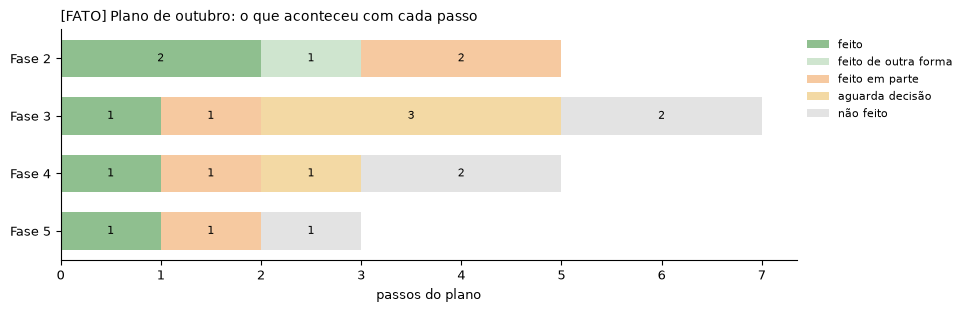

descricao  \
fase   passo                                                                                                           
Fase 2 2.1    Corrigir o pipeline: públicas, imputação no Pipeline, categóricas, sem vazamento, sem desfechos irmãos   
       2.2                                                                                  Baseline de persistência   
       2.3                                                                    Walk-forward com testes de 2021 a 2025   
       2.4                                                                   Decidir o pico de 2022 com o orientador   
       2.5                                                                                    Congelar a metodologia   
Fase 3 3.1                                                                Escola indígena e localização diferenciada   
       3.2                                                                                Indicador de elegibilidade   
       3.3                                                                                             Multisseriada   
       3.4                                                                                       IED 2019–2020 e HAD   
       3.5                                                                                                Pé-de-Meia   
       3.6                                                                                                      INSE   
       3.7                                                    Infraestrutura do Censo (prioridade 7 do relatório 02)   
Fase 4 4.1                                                                                      Definir 'alto risco'   
       4.2                                                                                   Treinar classificadores   
       4.3                                                                      Métricas de classificação e Recall@K   
       4.4                                                                   Comparar com ordenar pelo abandono de t   
       4.5                                                                                Análise de erros por grupo   
Fase 5 5.1                                                  Refinamento: hiperparâmetros, importância, SHAP, AF × EM   
       5.2                                                                                         Reprodutibilidade   
       5.3                                                                    Artigo da disciplina e relatório PIBIC   

                            estado  \
fase   passo                         
Fase 2 2.1    feito de outra forma   
       2.2                   feito   
       2.3          feito em parte   
       2.4                   feito   
       2.5          feito em parte   
Fase 3 3.1         aguarda decisão   
       3.2         aguarda decisão   
       3.3         aguarda decisão   
       3.4          feito em parte   
       3.5               não feito   
       3.6               não feito   
       3.7                   feito   
Fase 4 4.1         aguarda decisão   
       4.2               não feito   
       4.3          feito em parte   
       4.4                   feito   
       4.5               não feito   
Fase 5 5.1          feito em parte   
       5.2                   feito   
       5.3               não feito   

                                                                                                                                            como  
fase   passo                                                                                                                                      
Fase 2 2.1    o protocolo de gustavo/avaliacao filtra as públicas, imputa dentro do Pipeline e não tem vazamento (teste 04); não usa categóricas  
       2.2                                                                                                             B0, B1, B1R, B1R_lag e B2  
       2.3                               

In [3]:
r = t["resumo"]
r = r[r["registro"] == "plano_outubro"].pivot(index="grupo", columns="estado", values="n").fillna(0)
ordem = [e for e in ["feito", "feito de outra forma", "feito em parte", "aguarda decisão", "não feito"] if e in r.columns]
r = r[ordem].iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 3.0))
esquerda = pd.Series(0.0, index=r.index)
for e in ordem:
    ax.barh(r.index, r[e], left=esquerda, color=D.COR_ESTADO[e], label=e, height=0.65)
    for i, (v, l0) in enumerate(zip(r[e], esquerda)):
        if v:
            ax.text(l0 + v / 2, i, f"{int(v)}", ha="center", va="center", fontsize=8)
    esquerda = esquerda + r[e]
ax.set_xlabel("passos do plano")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)
F.titulo(ax, "Plano de outubro: o que aconteceu com cada passo", "FATO")
F.salvar(fig, FIGURAS, "07_plano_outubro")
plt.show()
t["outubro"].set_index(["fase", "passo"])[["descricao", "estado", "como"]]

**Leitura:**

- **A Fase 2 foi cumprida pelo protocolo de 02/11**, que fez mais do que o plano pedia: B1R_lag, bootstrap e
  Holm. Ficou de fora a dobra de 2025, que é o teste bloqueado.
- **A Fase 3 parou na decisão:** quase tudo nela depende do orientador (D8, D9, P017, P019).
- **As Fases 4 e 5** ficaram com o que o protocolo já entregava (Recall@K, importância, reprodutibilidade).

## 3. A estratégia do orientador (proposta de 17/09, `docs/README.md` §10)

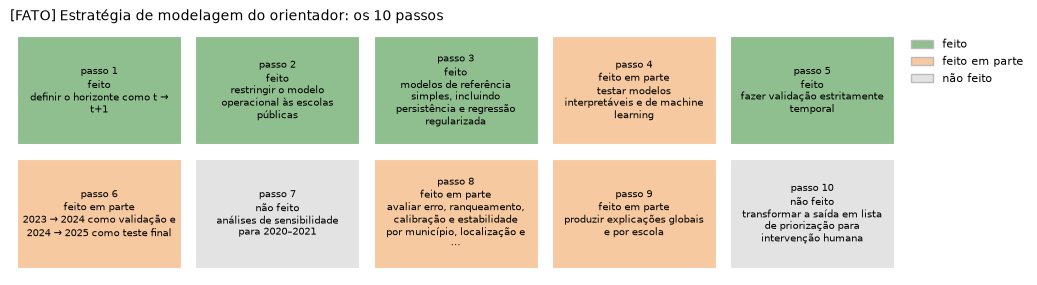

,recomendacao,estado,como
item,,,
1,definir o horizonte como t → t+1,feito,preditores de t e desfecho de t+1 (regra 4)
2,restringir o modelo operacional às escolas públicas,feito,universo = públicas com o desfecho de t+1 (D3)
3,"modelos de referência simples, incluindo persistência e regressão regularizada",feito,"B0, B1, B1R, B1R_lag e B2; Ridge com α fixo"
4,testar modelos interpretáveis e de machine learning,feito em parte,"Ridge e árvore rasa; Random Forest, boosting, GAM e EBM não rodados"
5,fazer validação estritamente temporal,feito,"walk-forward com janela expansiva, testes 2021–2024"
6,2023 → 2024 como validação e 2024 → 2025 como teste final,feito em parte,"2023→2024 é a última dobra do walk-forward; 2024→2025 está bloqueado no protocolo, mas os notebooks de outubro já testaram modelos nele"
7,análises de sensibilidade para 2020–2021,não feito,sensibilidade S1–S4 (D6) não rodada
8,"avaliar erro, ranqueamento, calibração e estabilidade por município, localização e dependência",feito em parte,erro e ranqueamento (Recall@K) feitos; calibração e estabilidade por grupo não; território e rede só no B2
9,produzir explicações globais e por escola,feito em parte,importância por permutação de grupo (global); nada por escola


In [4]:
o = t["orientador"]
fig, ax = plt.subplots(figsize=(11.5, 3.2))
rot = o["recomendacao"]
D.grade_estados(ax, o["item"].map(lambda i: f"passo {i}"), o["estado"], colunas=5, notas=rot, tamanho=8.5)
F.titulo(ax, "Estratégia de modelagem do orientador: os 10 passos", "FATO")
F.salvar(fig, FIGURAS, "07_estrategia_orientador")
plt.show()
o.set_index("item")[["recomendacao", "estado", "como"]]

**O que mais falta da estratégia do orientador:**

- a **sensibilidade de 2020–2021** (passo 7), já decidida na D6;
- **calibração e estabilidade por grupo** (passo 8);
- **explicação por escola** (passo 9);
- a **lista de priorização** para intervenção humana (passo 10), que é o produto final.

O passo 6 (2024→2025 como teste final) está bloqueado, e a divergência 1 do notebook 06 afeta o seu papel.

## 4. Os critérios de aceite da fase 1 (`CLAUDE.md` §8)

A fase 1 era "regerar a base longitudinal".

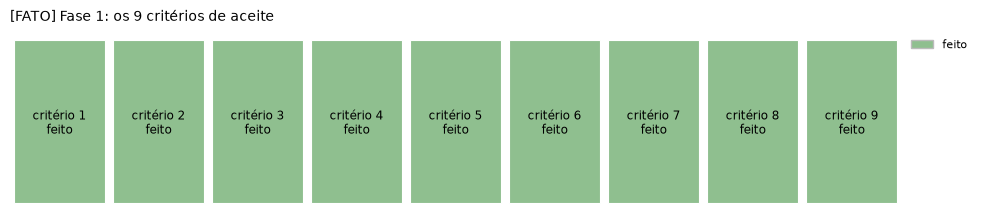

,descricao,estado,evidencia
criterio,,,
1,src/base_longitudinal.py regera a base a partir de dados/interim/indicadores_rr/,feito,2026-09-30; CLAUDE.md §8
2,a base regerada bate com a v1.0 do orientador nas 59 colunas,feito,docs/comparacao_base_v1.csv: 49 colunas idênticas e 8 na tolerância de 1e-9
3,as validações do validacao_base_longitudinal.json rodam por código e passam,feito,assert no módulo; CLAUDE.md §8
4,Parquet + CSV com chave única e hash no MANIFEST.csv,feito,dados/processado/ (2 arquivos no manifesto)
5,docs/desfechos.csv e docs/dicionario_anotado.csv gerados da metodologia,feito,59 variáveis vigentes + 7 propostas
6,DECISOES.md com entradas datadas para D1–D7 e para o que for aprovado de D8–D9,feito,"D1–D7 retroativas, criadas em 03/11; nada de D8–D9 foi aprovado"
7,"notebooks/01_leitura_e_recorte.ipynb roda de ponta a ponta, com o kernel reiniciado",feito,"9 células executadas em ordem (1 a 9), sem erro; a pasta notebooks/ ainda não está no git"
8,"nenhum arquivo de origem/, bruto/ ou externo/ modificado; nenhum microdado no git",feito,conferido em 30/09 pelo manifesto; reconferível a qualquer momento
9,um clone limpo chega ao mesmo estado pelo bootstrap,feito,36 min com --origem-local (30/09); o caminho --baixar só foi testado contra servidor falso


In [5]:
c = t["criterios"]
fig, ax = plt.subplots(figsize=(11.5, 2.4))
D.grade_estados(ax, c["criterio"].map(lambda i: f"critério {i}"), c["estado"], colunas=9, tamanho=8.5)
F.titulo(ax, "Fase 1: os 9 critérios de aceite", "FATO")
F.salvar(fig, FIGURAS, "07_criterios_fase1")
plt.show()
c.set_index("criterio")[["descricao", "estado", "evidencia"]]

A fase 1 está **cumprida**. Dois pontos ficaram soltos:

- o notebook do critério 7 existe e roda, mas a pasta `notebooks/` não está no git;
- o caminho `--baixar` do bootstrap só foi testado contra um servidor falso.

## 5. O Plano avançado de 07/10

`Relatórios do Projeto/Plano avançado do Claude.pdf` (11 páginas, 07/10/2026, compartilhado pelo Gustavo). É
um plano gerado por assistente (Claude) a partir do repositório e de um script de diagnóstico
(`old/diagnosticos_plano.py`, saídas em `old/diagnosticos_saida/`). O texto foi lido nesta revisão. **Os
números dele não foram reproduzidos** e devem ser tratados como [EXPLORATÓRIO]: usam todos os anos, inclusive
2025.

**O que ele propôs:**

- **mudar a pergunta** para "quanto do abandono é previsível, que alvo priorizar e quem cada critério deixa
  de fora";
- usar como **baseline a bater** uma taxa acumulada com encolhimento empírico-bayesiano, em vez da
  persistência;
- trocar o **desfecho principal** para a **contagem esperada** de abandonos e a métrica para a "captura de
  alunos@K";
- fechar o artigo com um **teste prospectivo**: previsões para 2026 seladas com hash antes de o INEP
  publicar;
- dez trilhas de trabalho (T0 a T9): protocolo, base com contagens, teto de previsibilidade, previsores
  parcimoniosos, avaliação por decisão, série longa, enriquecimento, Roraima em contexto, evasão,
  observatório e piloto.

**Treze achados exploratórios do plano** (não conferidos aqui):

- as escolas são pequenas: mediana de 80 alunos no AF e 62 no EM;
- só parte da variação é previsível: 37–38% persistente entre escolas, 23–28% ruído binomial;
- a lista por taxa regride à média sem nenhuma intervenção, e por isso um piloto precisa de sorteio;
- a contagem pura quase exclui as escolas indígenas do EM;
- Roraima divergiu do Brasil no EM em 2025.

**O que aconteceu com as 10 decisões que ele levava ao orientador:**

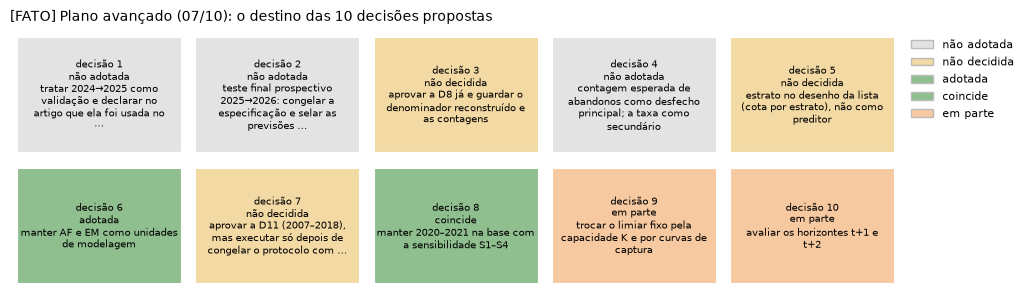

,recomendacao,estado,o_que_aconteceu
n,,,
1,tratar 2024→2025 como validação e declarar no artigo que ela foi usada no desenvolvimento,não adotada,"o protocolo manteve 2024→2025 como teste bloqueado (D7), e os documentos oficiais dizem que ela nunca avaliou modelo"
2,teste final prospectivo 2025→2026: congelar a especificação e selar as previsões com hash e data,não adotada,nenhum registro
3,aprovar a D8 já e guardar o denominador reconstruído e as contagens,não decidida,a D8 segue em aberto
4,contagem esperada de abandonos como desfecho principal; a taxa como secundário,não adotada,o desfecho segue sendo a taxa (D4); o peso por matrícula é proposta (P018)
5,"estrato no desenho da lista (cota por estrato), não como preditor",não decidida,"o estrato não é preditor (decisão de equidade, CLAUDE.md §6); cota não discutida"
6,manter AF e EM como unidades de modelagem,adotada,painéis AF e EM (D2)
7,"aprovar a D11 (2007–2018), mas executar só depois de congelar o protocolo com 2019–2025",não decidida,o protocolo foi congelado em 02/11; a D11 segue em aberto
8,manter 2020–2021 na base com a sensibilidade S1–S4,coincide,é a D6 do orientador; S1–S4 não rodadas
9,trocar o limiar fixo pela capacidade K e por curvas de captura,em parte,Recall@K com K = 10% e 20%; captura de alunos não; o limiar ALTO_* segue em aberto


In [6]:
a = t["avancado"]
fig, ax = plt.subplots(figsize=(11.5, 3.4))
D.grade_estados(ax, a["n"].map(lambda i: f"decisão {i}"), a["estado"], colunas=5,
                notas=a["recomendacao"], tamanho=8.5)
F.titulo(ax, "Plano avançado (07/10): o destino das 10 decisões propostas", "FATO")
F.salvar(fig, FIGURAS, "07_plano_avancado")
plt.show()
a.set_index("n")[["recomendacao", "estado", "o_que_aconteceu"]]

**O que o plano antecipou:**

- que a pergunta "qual algoritmo prevê melhor" não se sustentava. Em 02/11 o projeto também a abandonou, por
  outro caminho: identificar a informação que carrega sinal;
- que os modelos não superam a persistência de forma estável, o que o protocolo depois **mediu** com
  intervalo e Holm;
- que o teste 2024→2025 já tinha sido usado. Os documentos oficiais seguiram dizendo o contrário (notebook
  06, divergência 1).

**O que nunca foi discutido no registro:**

- a contagem como desfecho;
- o teste prospectivo;
- a cota por estrato;
- o horizonte *t*+2.

Esses pontos estão nas perguntas N2 e N4 do notebook 06.

## 6. Caminhos daqui em diante

O diagrama separa o que espera decisão do que pode andar sem decisão nova.

- **Coluna da esquerda:** decisões pendentes, com quem decide.
- **Coluna da direita:** o trabalho que cada uma destrava.
- **Faixa de baixo:** o que, **pela leitura dos registros**, pode andar sem decisão nova [INTERPRETAÇÃO]. Por
  exemplo, as S1–S4 já foram decididas na D6.

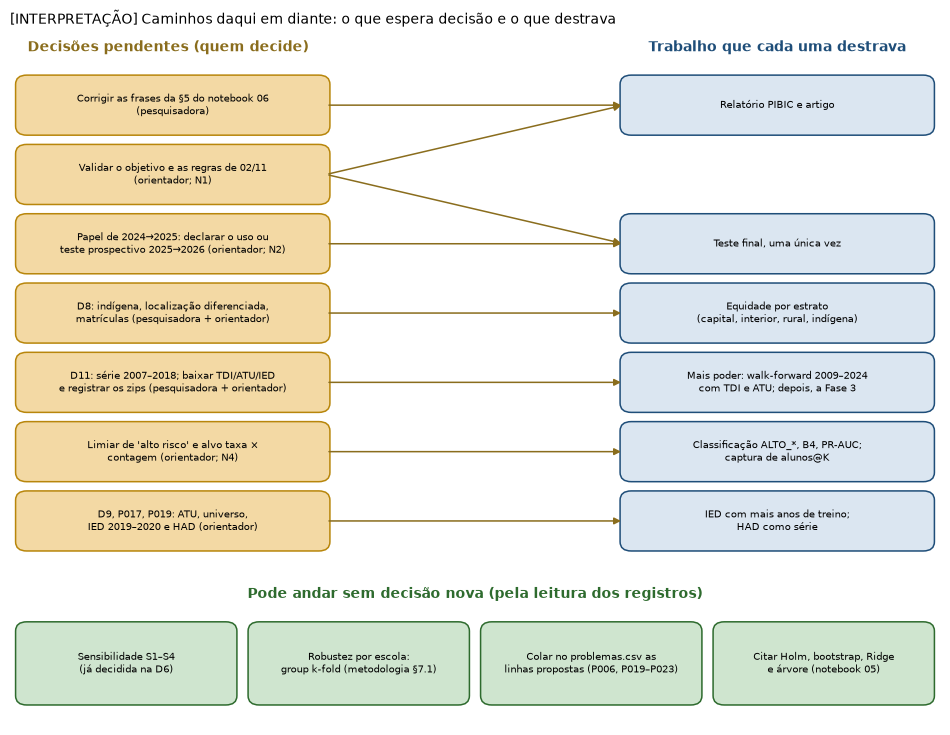

In [7]:
fig, ax = plt.subplots(figsize=(12, 9))
D.tela(ax, 100, 90)
ax.text(17, 87.5, "Decisões pendentes (quem decide)", ha="center", fontsize=10, fontweight="bold", color="#8a6d1d")
ax.text(82.5, 87.5, "Trabalho que cada uma destrava", ha="center", fontsize=10, fontweight="bold", color=D.AZUL)
dec = {
    "R": (77, "Corrigir as frases da §5 do notebook 06\n(pesquisadora)"),
    "A": (68, "Validar o objetivo e as regras de 02/11\n(orientador; N1)"),
    "B": (59, "Papel de 2024→2025: declarar o uso ou\nteste prospectivo 2025→2026 (orientador; N2)"),
    "C": (50, "D8: indígena, localização diferenciada,\nmatrículas (pesquisadora + orientador)"),
    "D": (41, "D11: série 2007–2018; baixar TDI/ATU/IED\ne registrar os zips (pesquisadora + orientador)"),
    "E": (32, "Limiar de 'alto risco' e alvo taxa ×\ncontagem (orientador; N4)"),
    "F": (23, "D9, P017, P019: ATU, universo,\nIED 2019–2020 e HAD (orientador)"),
}
trab = {
    "X5": (77, "Relatório PIBIC e artigo"),
    "X4": (59, "Teste final, uma única vez"),
    "X1": (50, "Equidade por estrato\n(capital, interior, rural, indígena)"),
    "X2": (41, "Mais poder: walk-forward 2009–2024\ncom TDI e ATU; depois, a Fase 3"),
    "X3": (32, "Classificação ALTO_*, B4, PR-AUC;\ncaptura de alunos@K"),
    "X6": (23, "IED com mais anos de treino;\nHAD como série"),
}
caixas = {}
for k, (y, txt) in dec.items():
    caixas[k] = D.caixa(ax, 1, y, 33, 7, txt, "decisao", tamanho=7.5, negrito_primeira=False)
for k, (y, txt) in trab.items():
    caixas[k] = D.caixa(ax, 66, y, 33, 7, txt, "oficial", tamanho=7.5, negrito_primeira=False)
for o_, d_ in [("R", "X5"), ("A", "X5"), ("A", "X4"), ("B", "X4"), ("C", "X1"), ("D", "X2"), ("E", "X3"), ("F", "X6")]:
    D.seta(ax, D.centro(caixas[o_], "d"), D.centro(caixas[d_], "e"), cor="#8a6d1d")
ax.text(50, 16.5, "Pode andar sem decisão nova (pela leitura dos registros)", ha="center", fontsize=10,
        fontweight="bold", color="#2e6b2e")
livres = ["Sensibilidade S1–S4\n(já decidida na D6)", "Robustez por escola:\ngroup k-fold (metodologia §7.1)",
          "Colar no problemas.csv as\nlinhas propostas (P006, P019–P023)", "Citar Holm, bootstrap, Ridge\ne árvore (notebook 05)"]
for i, txt in enumerate(livres):
    D.caixa(ax, 1 + i * 25, 3, 23, 10, txt, "livre", tamanho=7.5, negrito_primeira=False)
F.titulo(ax, "Caminhos daqui em diante: o que espera decisão e o que destrava", "INTERPRETAÇÃO")
F.salvar(fig, FIGURAS, "07_caminhos")
plt.show()

**Por que a faixa de baixo não espera ninguém:**

- **S1–S4:** a D6 do orientador já manda rodá-las, e elas não tocam 2025.
- ***Group k-fold* por escola:** está na metodologia (§7.1) como robustez.
- **Linhas propostas do `problemas.csv`:** colar é tarefa da pesquisadora. A P027 fica de fora: ela espera a
  correção da divergência 1.
- **Citações:** são de método, não mudam resultado.

Mesmo assim, "não precisa de decisão nova" é uma leitura deste notebook, não uma regra. Se alguma delas
mudar o que a pesquisa afirma, vale o `CLAUDE.md` §6.

**Fase 3 (variáveis novas):** fica suspensa até o instrumento separar alguma coisa, o que depende de mais
poder (D11) ou de outro desenho de avaliação (pergunta N3 do notebook 06).

## 7. Quando o INEP publicar os indicadores de 2026

A proposta do orientador (§14) já diz o que fazer. A data não é conhecida: o rendimento de 2025 já estava no
projeto em 09/09/2026, segundo o `MANIFEST.csv`.

| Passo (proposta §14) | No projeto |
|---|---|
| incluir 2026 como novo ano de indicadores | baixar como **arquivo novo** exige decisão (`CLAUDE.md` §6); entra pelo manifesto (regra 1) |
| gerar o desfecho *t*+1 das linhas de 2025 | `src/base_longitudinal.py` regera; o hash da base no manifesto muda (aviso, não erro) |
| manter 2026 sem desfecho até 2027 | igual ao que acontece hoje com 2025 |
| repetir as verificações de integridade | os 70 testes pytest, os 7 relatórios de checks e a comparação com a v1.0 |
| não sobrescrever versões anteriores | regra 1; versão fixada pelo sha256 |
| registrar data, fontes e mudanças | `DECISOES.md` e `MANIFEST.csv` |

Se a resposta à pergunta N2 for o teste prospectivo, as previsões para 2026 precisam ser **seladas antes**
dessa publicação.

## 8. Resumo: o que fazer agora

**Sem decisão nova:**

1. rodar as S1–S4 e a robustez por escola;
2. colar as linhas propostas no `problemas.csv`;
3. citar os métodos usados.

**Com decisão, nesta ordem de dependência:**

1. corrigir as frases da divergência 1 a 4 (pesquisadora);
2. levar ao orientador a validação do objetivo e das regras de 02/11 (N1) e o papel do teste final (N2);
3. decidir D8 e D11;
4. só então voltar a enriquecer a base (Fase 3) ou abrir o teste final.

A escrita do relatório PIBIC e do artigo depende de N1: é ela que fixa o que a pesquisa afirma.